In [3]:
import pandas as pd
import matplotlib.pyplot as plt

df_ventas = pd.read_csv(
    "../data/processed/online_retail_ventas.csv",
    parse_dates=["InvoiceDate"],
    dtype={
        "InvoiceNo": "string",
        "StockCode": "string",
        "CustomerID": "string"
    }
)

display(df_ventas.head())

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,EsCancelacion,CantidadNegativa,PrecioNoPositivo,Anio,Mes,ImporteLinea
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,False,False,False,2010,12,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,False,False,2010,12,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,False,False,False,2010,12,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,False,False,2010,12,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,False,False,2010,12,20.34


In [4]:
from pathlib import Path

archivo = Path("../data/processed/online_retail_ventas.csv")

print("¿Existe el archivo?", archivo.exists())

¿Existe el archivo? True


In [5]:
display(df_ventas.shape)

(530104, 14)

In [6]:
facturacion_total = df_ventas["ImporteLinea"].sum()

print(f"Facturación bruta seleccionada: {facturacion_total:,.2f} £")

Facturación bruta seleccionada: 10,666,684.54 £


In [7]:
display(df_ventas["InvoiceNo"].count())

np.int64(530104)

In [8]:
pedidos_unicos = df_ventas["InvoiceNo"].nunique()

print(f"Pedidos únicos: {pedidos_unicos}")

Pedidos únicos: 19960


In [9]:
ticket_medio = facturacion_total / pedidos_unicos

print(f"Ticket medio: {ticket_medio:.2f} £")

Ticket medio: 534.40 £


In [10]:
df_ventas["Periodo"] = df_ventas["InvoiceDate"].dt.to_period("M")

display(df_ventas[["InvoiceDate", "Periodo"]].head())

,InvoiceDate,Periodo
0,2010-12-01 08:26:00,2010-12
1,2010-12-01 08:26:00,2010-12
2,2010-12-01 08:26:00,2010-12
3,2010-12-01 08:26:00,2010-12
4,2010-12-01 08:26:00,2010-12


In [11]:
ventas_mensuales = df_ventas.groupby("Periodo")["ImporteLinea"].sum()

ventas_mensuales = ventas_mensuales.sort_index()

display(ventas_mensuales)

Periodo
2010-12     823746.140
2011-01     691364.560
2011-02     523631.890
2011-03     717639.360
2011-04     537808.621
2011-05     770536.020
2011-06     761739.900
2011-07     719221.191
2011-08     759138.380
2011-09    1058590.172
2011-10    1154979.300
2011-11    1509496.330
2011-12     638792.680
Freq: M, Name: ImporteLinea, dtype: float64

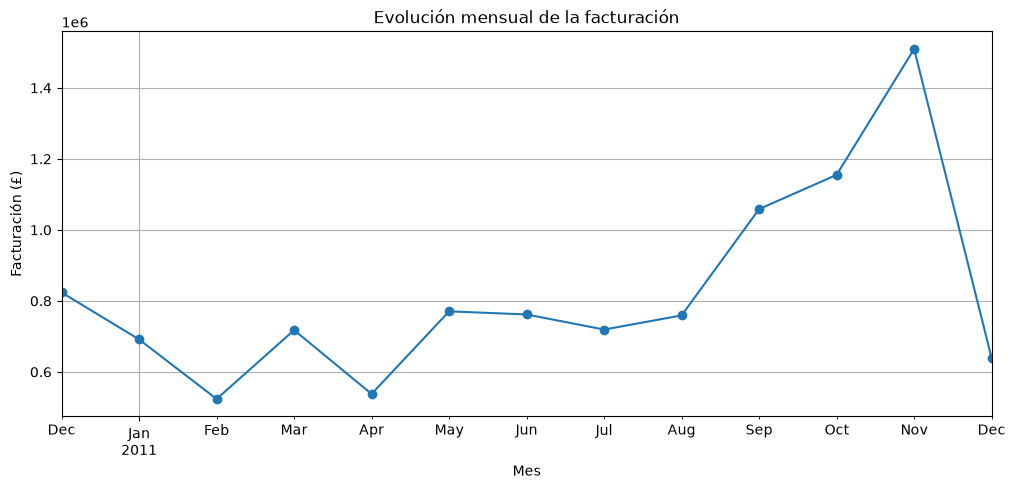

In [12]:
ventas_mensuales.plot(
    kind="line",
    figsize=(12, 5),
    marker="o"
)

plt.title("Evolución mensual de la facturación")
plt.xlabel("Mes")
plt.ylabel("Facturación (£)")
plt.grid(True)
plt.show()

In [13]:
ventas_producto = df_ventas.groupby("StockCode")["ImporteLinea"].sum()

ventas_producto = ventas_producto.sort_values(
    ascending=False
)

display(ventas_producto.head(10))

StockCode
DOT       206248.77
22423     174484.74
23843     168469.60
85123A    104518.80
47566      99504.33
85099B     94340.05
23166      81700.92
M          78110.27
POST       78101.88
23084      66964.99
Name: ImporteLinea, dtype: float64

In [14]:
ventas_pais = df_ventas.groupby("Country")["ImporteLinea"].sum()

ventas_pais = ventas_pais.sort_values(
    ascending=False
)

display(ventas_pais.head(10))

Country
United Kingdom    9025222.084
Netherlands        285446.340
EIRE               283453.960
Germany            228867.140
France             209715.110
Australia          138521.310
Spain               61577.110
Switzerland         57089.900
Belgium             41196.340
Sweden              38378.330
Name: ImporteLinea, dtype: float64

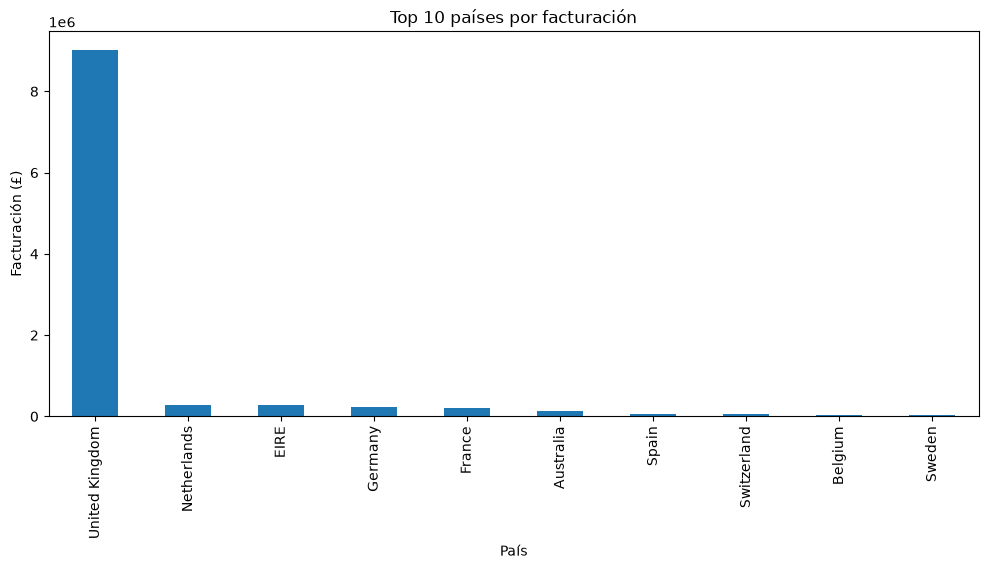

In [15]:
ventas_pais.head(10).plot(
    kind="bar",
    figsize=(12, 5)
)

plt.title("Top 10 países por facturación")
plt.xlabel("País")
plt.ylabel("Facturación (£)")
plt.show()

In [16]:
unidades_vendidas = df_ventas["Quantity"].sum()

display(unidades_vendidas)

np.int64(5588376)

In [17]:
clientes_diferentes = df_ventas["CustomerID"].nunique()

display(clientes_diferentes)

4338

In [20]:
facturacion_total = df_ventas["ImporteLinea"].sum()
facturacion_uk = (df_ventas[df_ventas['Country'] == 'United Kingdom']['ImporteLinea'].sum() / facturacion_total) * 100

display(facturacion_uk)

np.float64(84.61131522893568)

In [21]:
mes_mas_facturacion = ventas_mensuales.sort_values(ascending=False).head(1)

display(mes_mas_facturacion)

Periodo
2011-11    1509496.33
Freq: M, Name: ImporteLinea, dtype: float64